# mlfilter-scale: 論文用の図

入力の run と SHA-256 は `analysis_config.json` と `csv/input_manifest.json`。追加の計算は `experiments/mlfilter-scale/paper_extra.json`(探索的な追加解析で、確認実験の事前固定の検定とは別)。

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
import plot, matplotlib, csv
from IPython.display import Image, display
print('python', sys.executable, '| matplotlib', matplotlib.__version__)
plot.build_csv()

python /home/jovyan/FMA/.venv/bin/python | matplotlib 3.11.1


CSV written: classical_fixed.csv, classical_loop.csv, compute_cost.csv, confirm2_curves.csv, confirm2_final.csv, confirm_final_ranks.csv, confirm_mechanism_per_cycle.csv, energy_hist.csv, explore_curves.csv, fixedfm_schedules.csv, loop_alpha_sweep.csv


## 図 1: 概念図(`concept`)
- (a)(b) 縦軸: ソルバーから見た正規化エネルギー(最大係数で割った値)。黒丸 = 制約を満たす状態、橙の × = その間にある違反状態(実行可能な状態間の移動は違反状態を経由する)。(a) α が小さいと違反状態の方が低くなり、違反解へ落ちる。(b) α が大きいと違反状態が高い壁になり、FM の差(黒丸の高さの違い)は相対的に縮んで平らになる
- (c) XY ミキサーは各層の One-Hot 状態(1000, 0100, …)の間だけを結ぶ(リング)。違反状態を通らない
- 限界: 模式図。エネルギーは説明用の値で、実験データではない

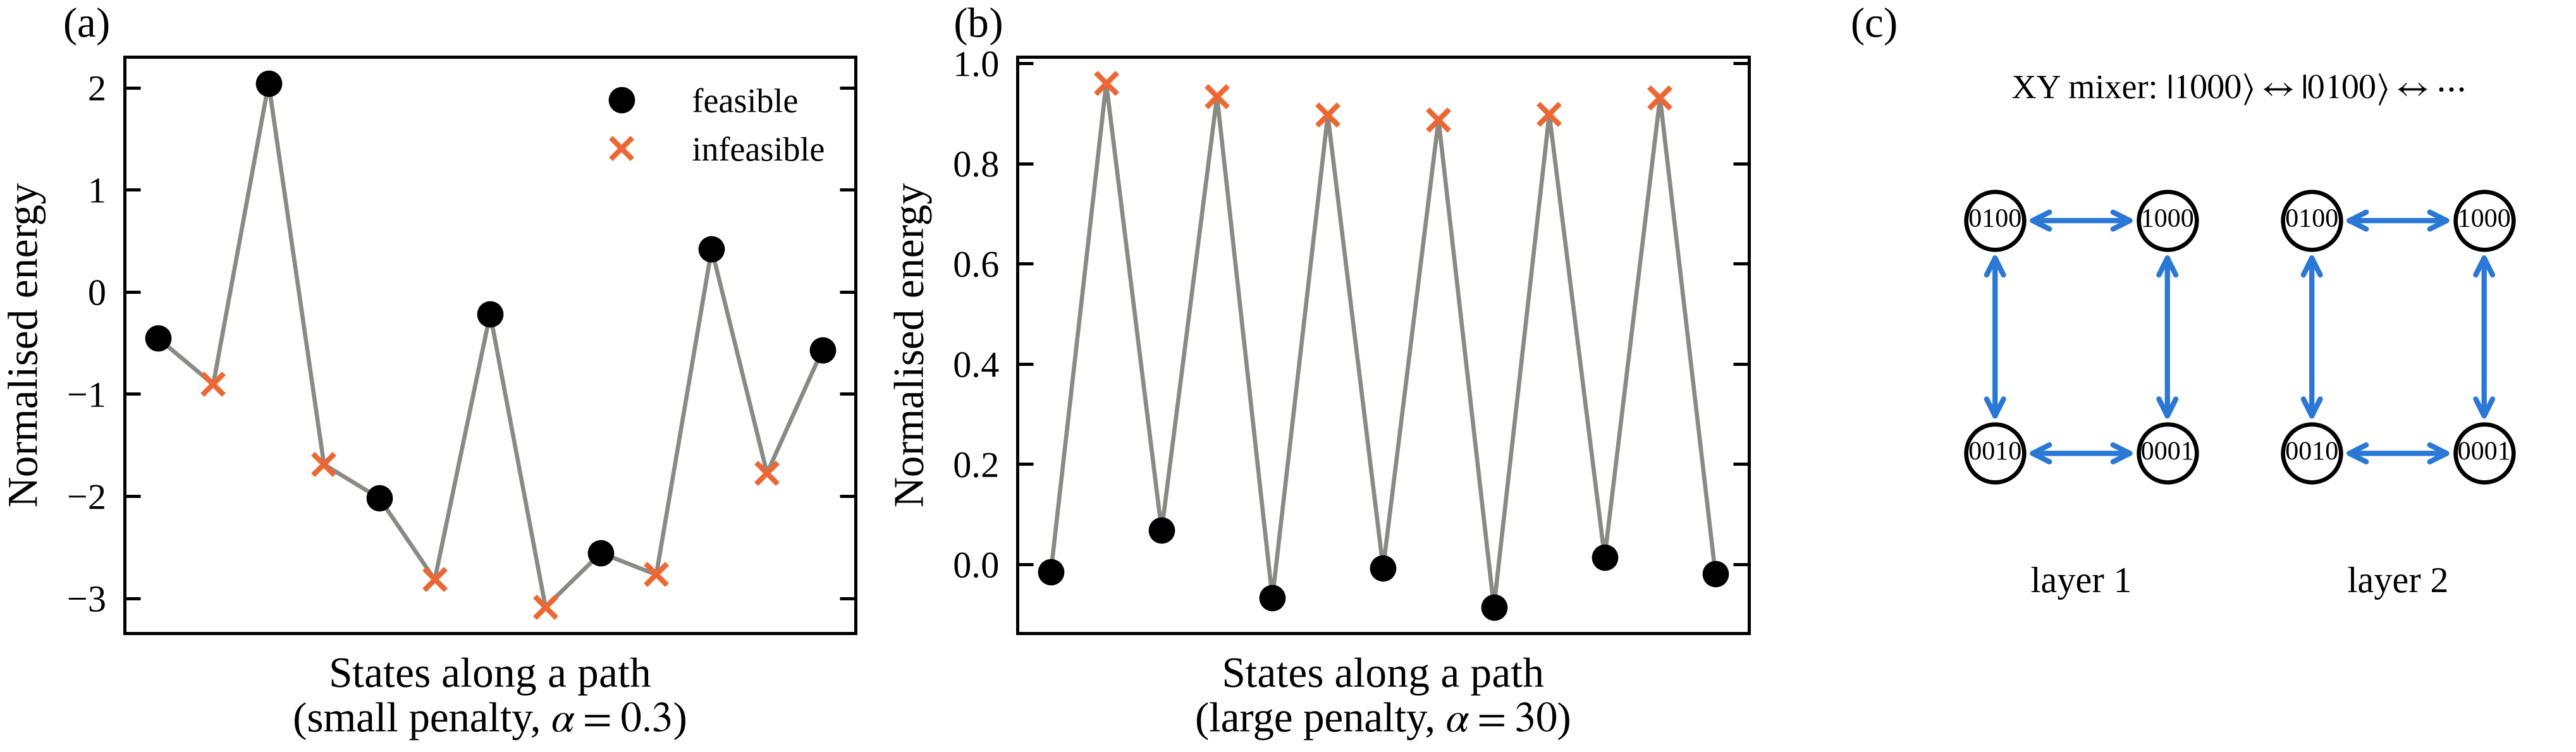

In [2]:
display(Image('png/concept.png'))

## 図 2: Seed ごとの対応(`paired_ranks`)
- 縦軸: 100 評価後の最良解の真の順位(対数、1 = 最適解、小さいほど良い)。左の点 = 比較手法、右の点 = XY-FMQAOA。線で同じ Seed を結ぶ。青 = XY が良い、灰 = 同順位、橙 = XY が悪い
- (a) α=0.3、(b) α=100、(c) α=1(調整済み)。確認実験(L=7、15 Seed)
- 見るところ: (a) 15 勝、(b) 13 勝 1 分 1 敗(事前固定の検定で支持)。(c) は 5 勝 8 分 2 敗で同程度

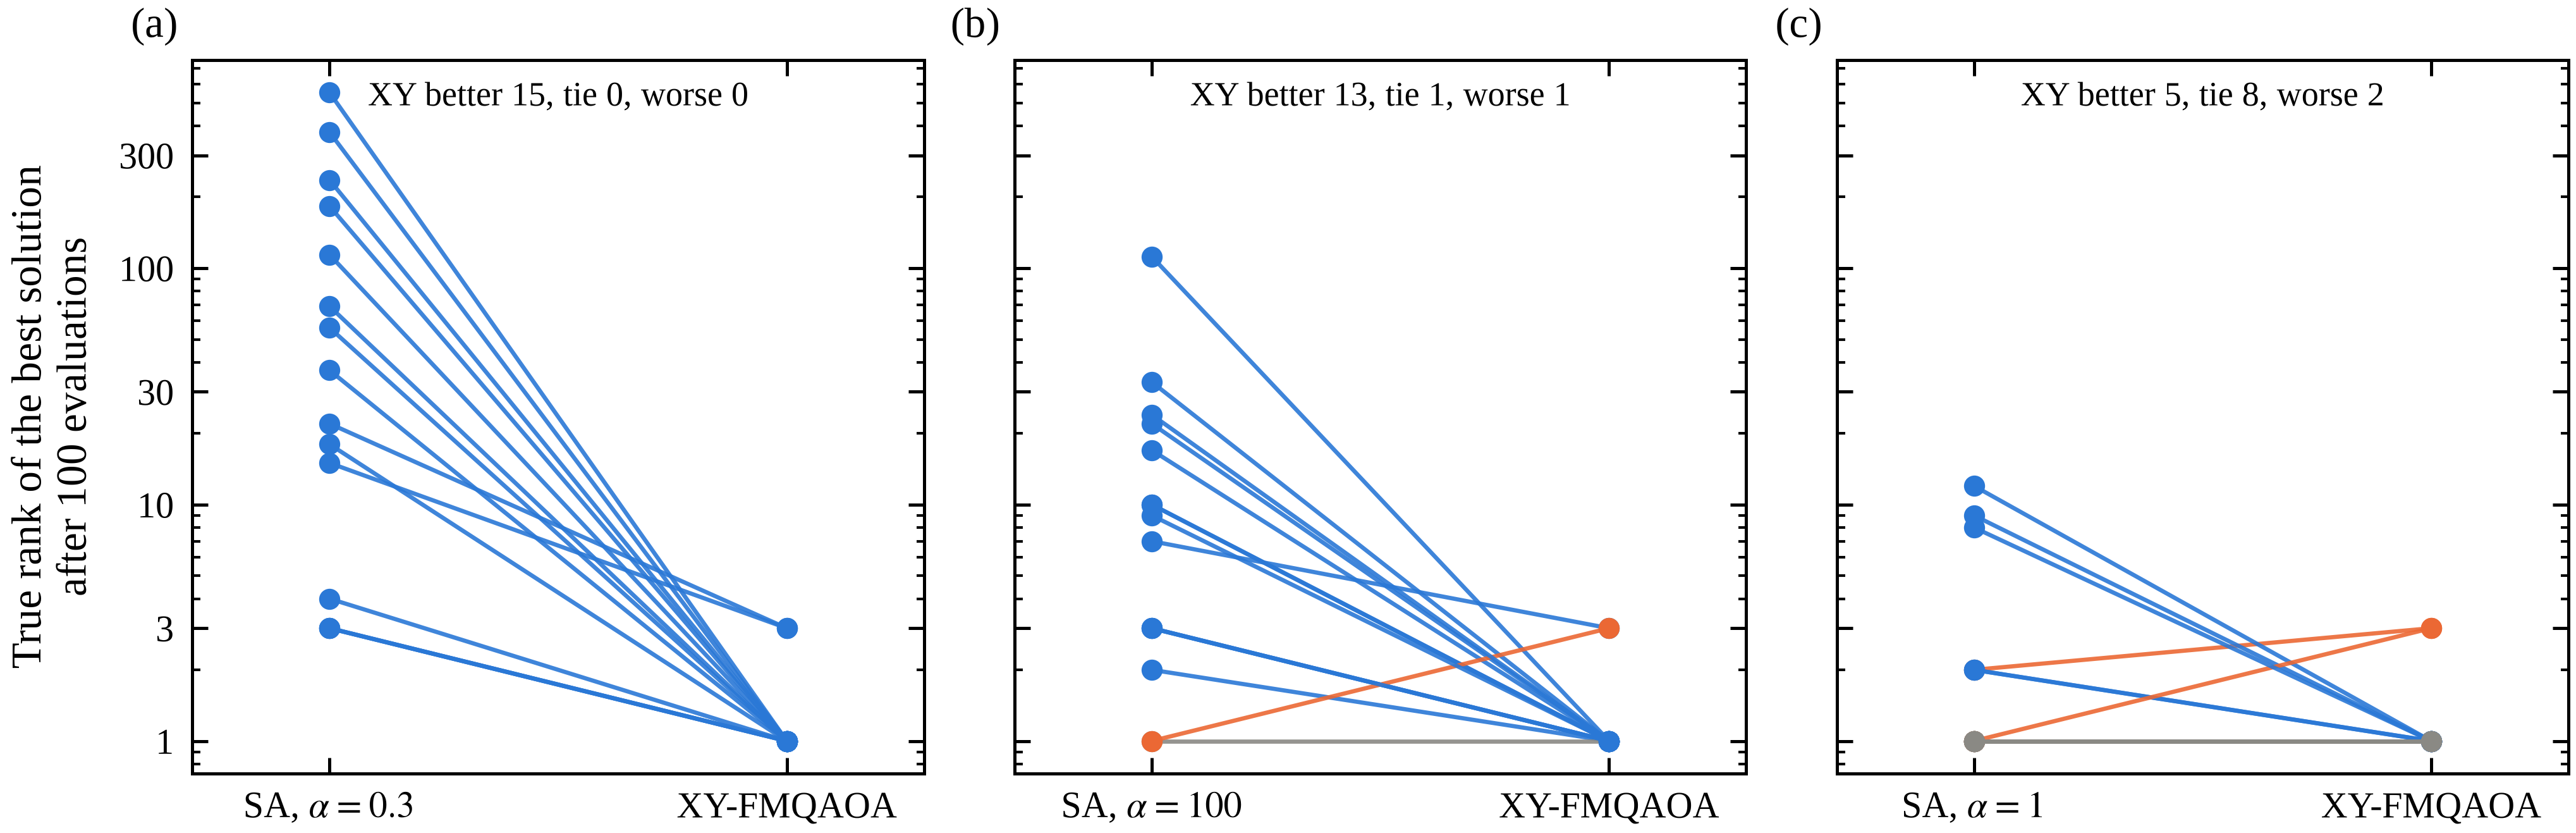

In [3]:
display(Image('png/paired_ranks.png'))

## 図 3: 閉ループの α 掃引(`loop_alpha_sweep`)
- 横軸: ペナルティ係数 α(対数)。縦軸: 100 評価後の最良解の真の順位(15 Seed の中央値、灰色の帯 = IQR)。青線 = XY-FMQAOA(α に依存しない)、点線 = α を自動調整する SA、灰色破線 = ランダム提案 + FM 選択
- 見るところ: SA は α=1 付近だけが良い U 字。α≥10 はランダム提案 + FM 選択と同程度、α=0.3 は大きく悪い。XY は調整なしで U 字の底と同じ水準(最適解到達は XY 13/15、自動調整 8/15、α=1 9/15)
- 限界: α=3・10・30・1000 と自動調整は追加の探索的解析(同じ 15 Seed)。検定はしていない

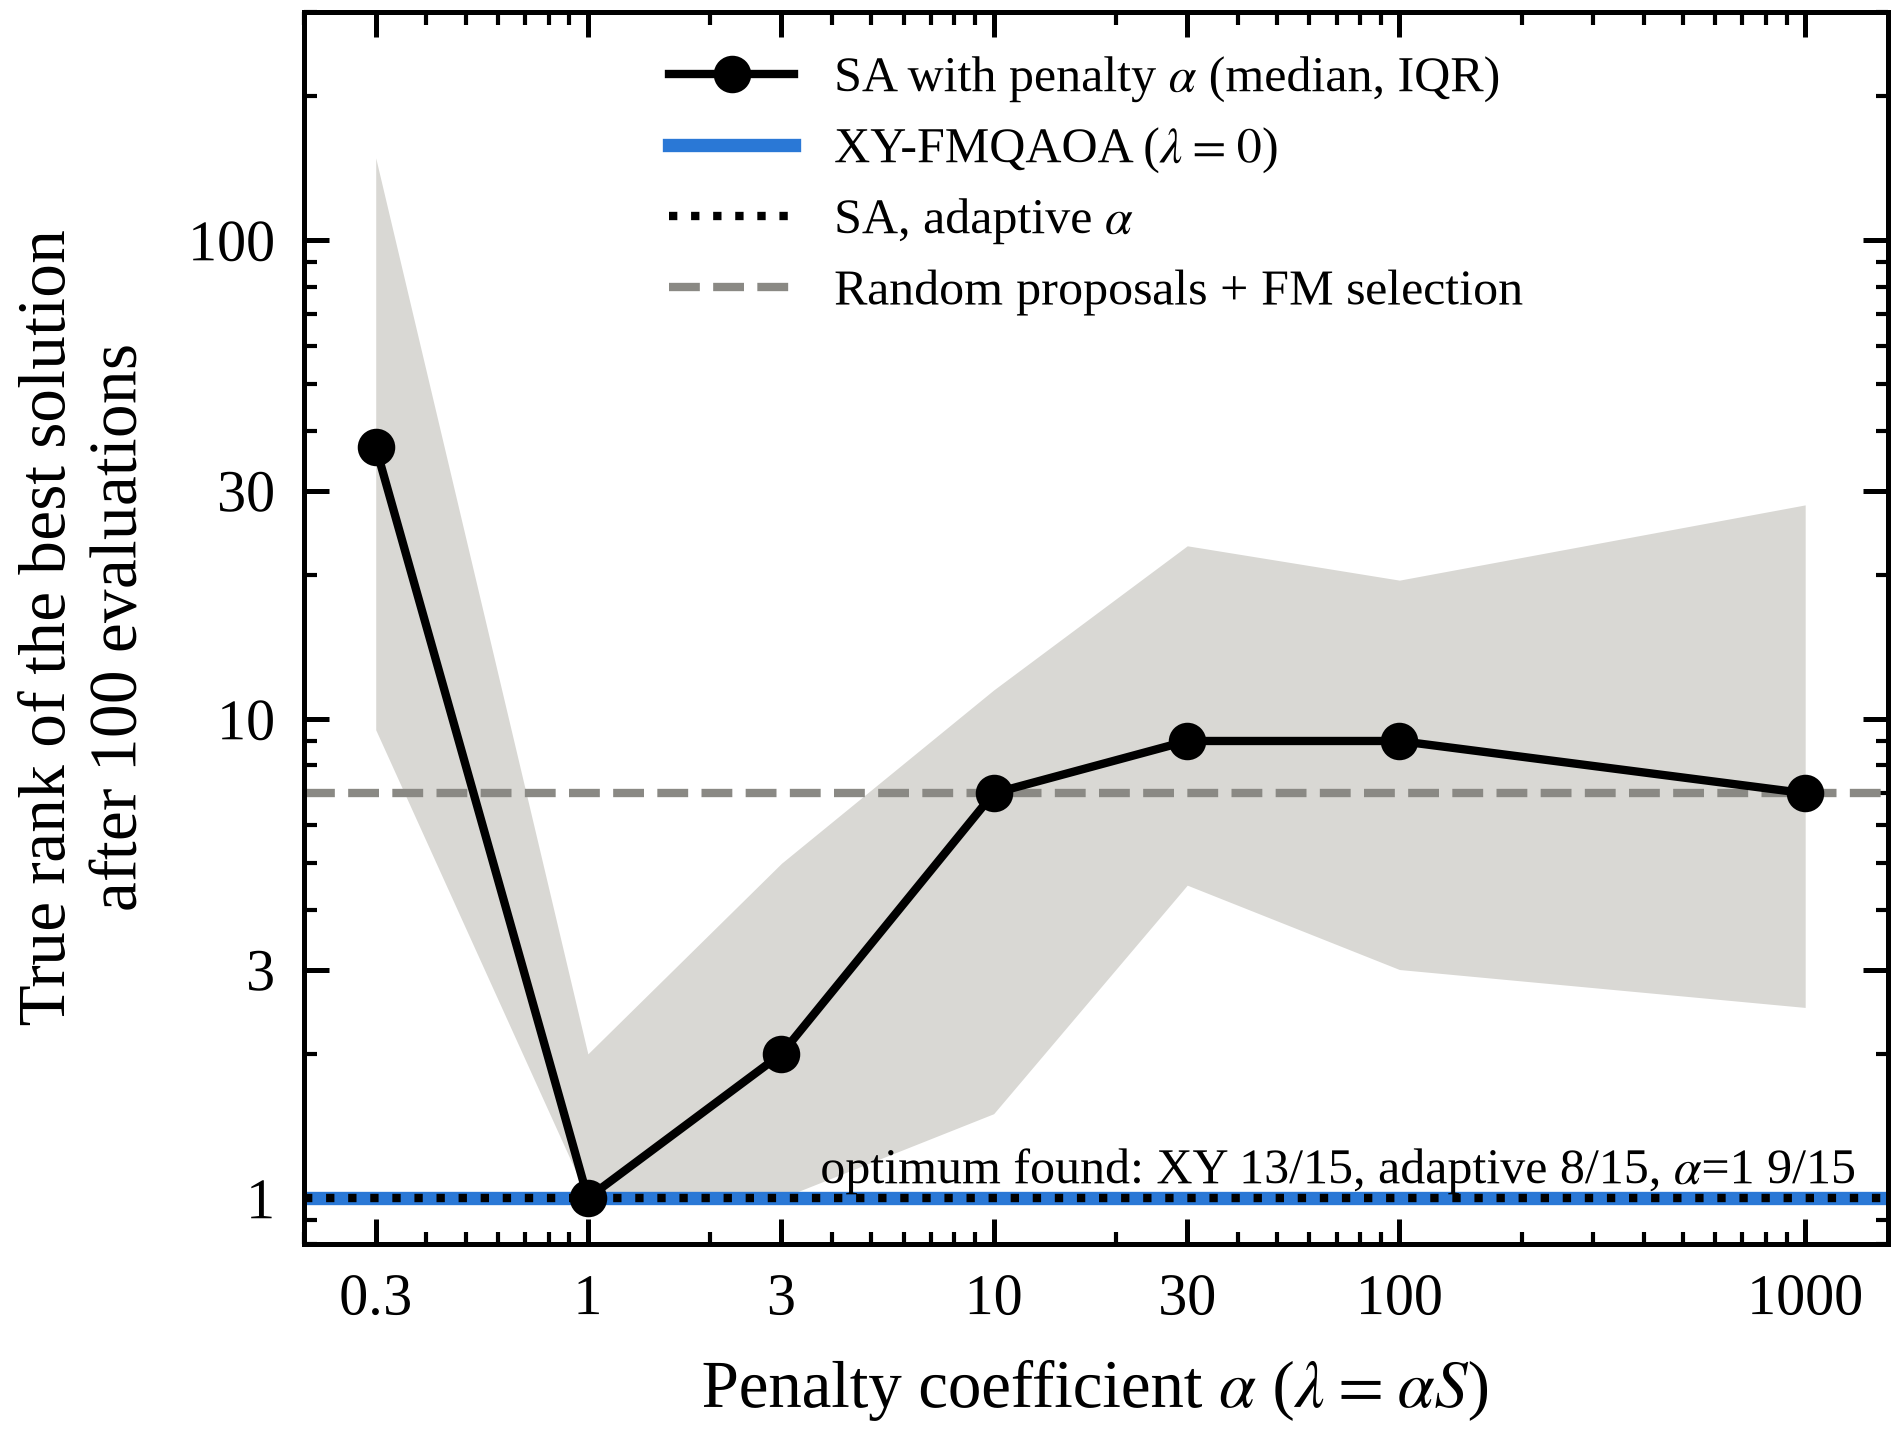

In [4]:
display(Image('png/loop_alpha_sweep.png'))

## 図 4: 温度を調整し直しても平準化は残るか(`retune_robustness`)
- (a)〜(c) 固定 FM(L=6・7・8、各 5 FM の中央値): SA が出した実行可能サンプルの FM 百分位(0 = FM 最良、0.5 = ランダム)を、温度の設定ごとに比べる。黒 = 自動設定(これまでと同じ)、橙 = FM の尺度に合わせた温度範囲、緑 = 自動設定で 10 倍の sweep、青菱形 = FM 尺度 + 10 倍。青の水平線 = XY-FMQAOA p=4、灰色破線 = ランダム
- (d) 閉ループ(L=7、15 Seed)の最良順位: α=100 を 4 通りの温度設定で、α=1 と XY と比べる。点 = Seed、横線 = 中央値
- 見るところ: α≥100 ではどの温度設定でも 0.45〜0.54 でランダムと同程度(平準化は温度の調整では解消しない)。α=10 では sweep を増やすと少し改善。閉ループでは温度を調整すると α=100 の中央値が 9 位 → 2〜4 位に改善するが、最適解の到達は 3〜4/15 で XY(13/15)に及ばない
- 限界: 試した温度設定は 3 通り。Neal の SA に限る

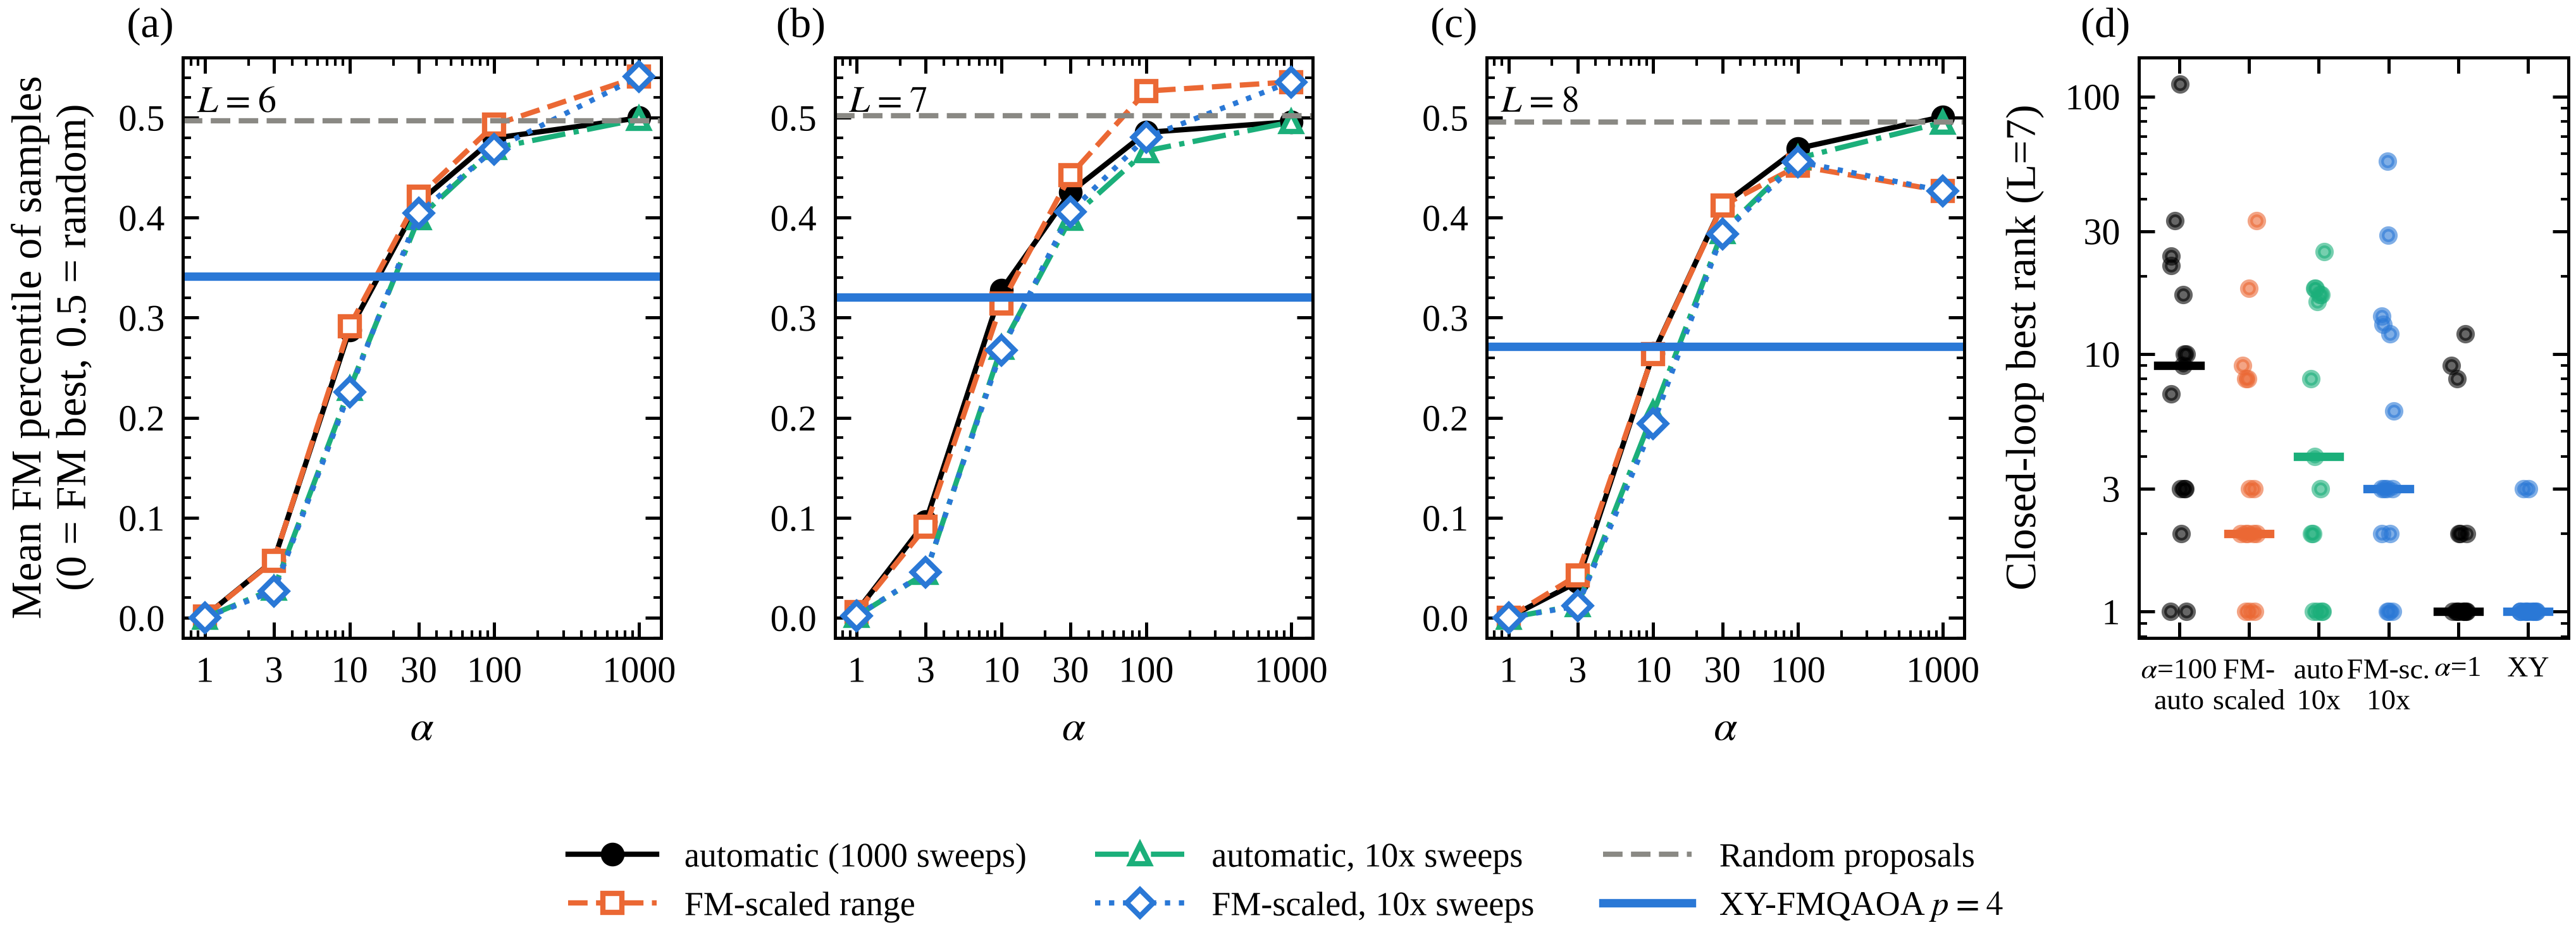

In [5]:
display(Image('png/retune_robustness.png'))

## 図 5: サンプルの FM 分布(`energy_hist`)
- 横軸: 実行可能なサンプル 1 つの FM 百分位(0 = FM 最良)。縦軸: 密度(対数)。L=7、5 FM × 10 reps を合わせた分布
- 見るところ: α=1 は FM の良い側に集中、α=100 は一様(ランダム)と重なり平らになる。XY は良い側に山を持ちつつ全体に広がる(閉ループでの多様な提案につながる)
- 限界: 固定 FM での分布。閉ループの各サイクルの分布ではない

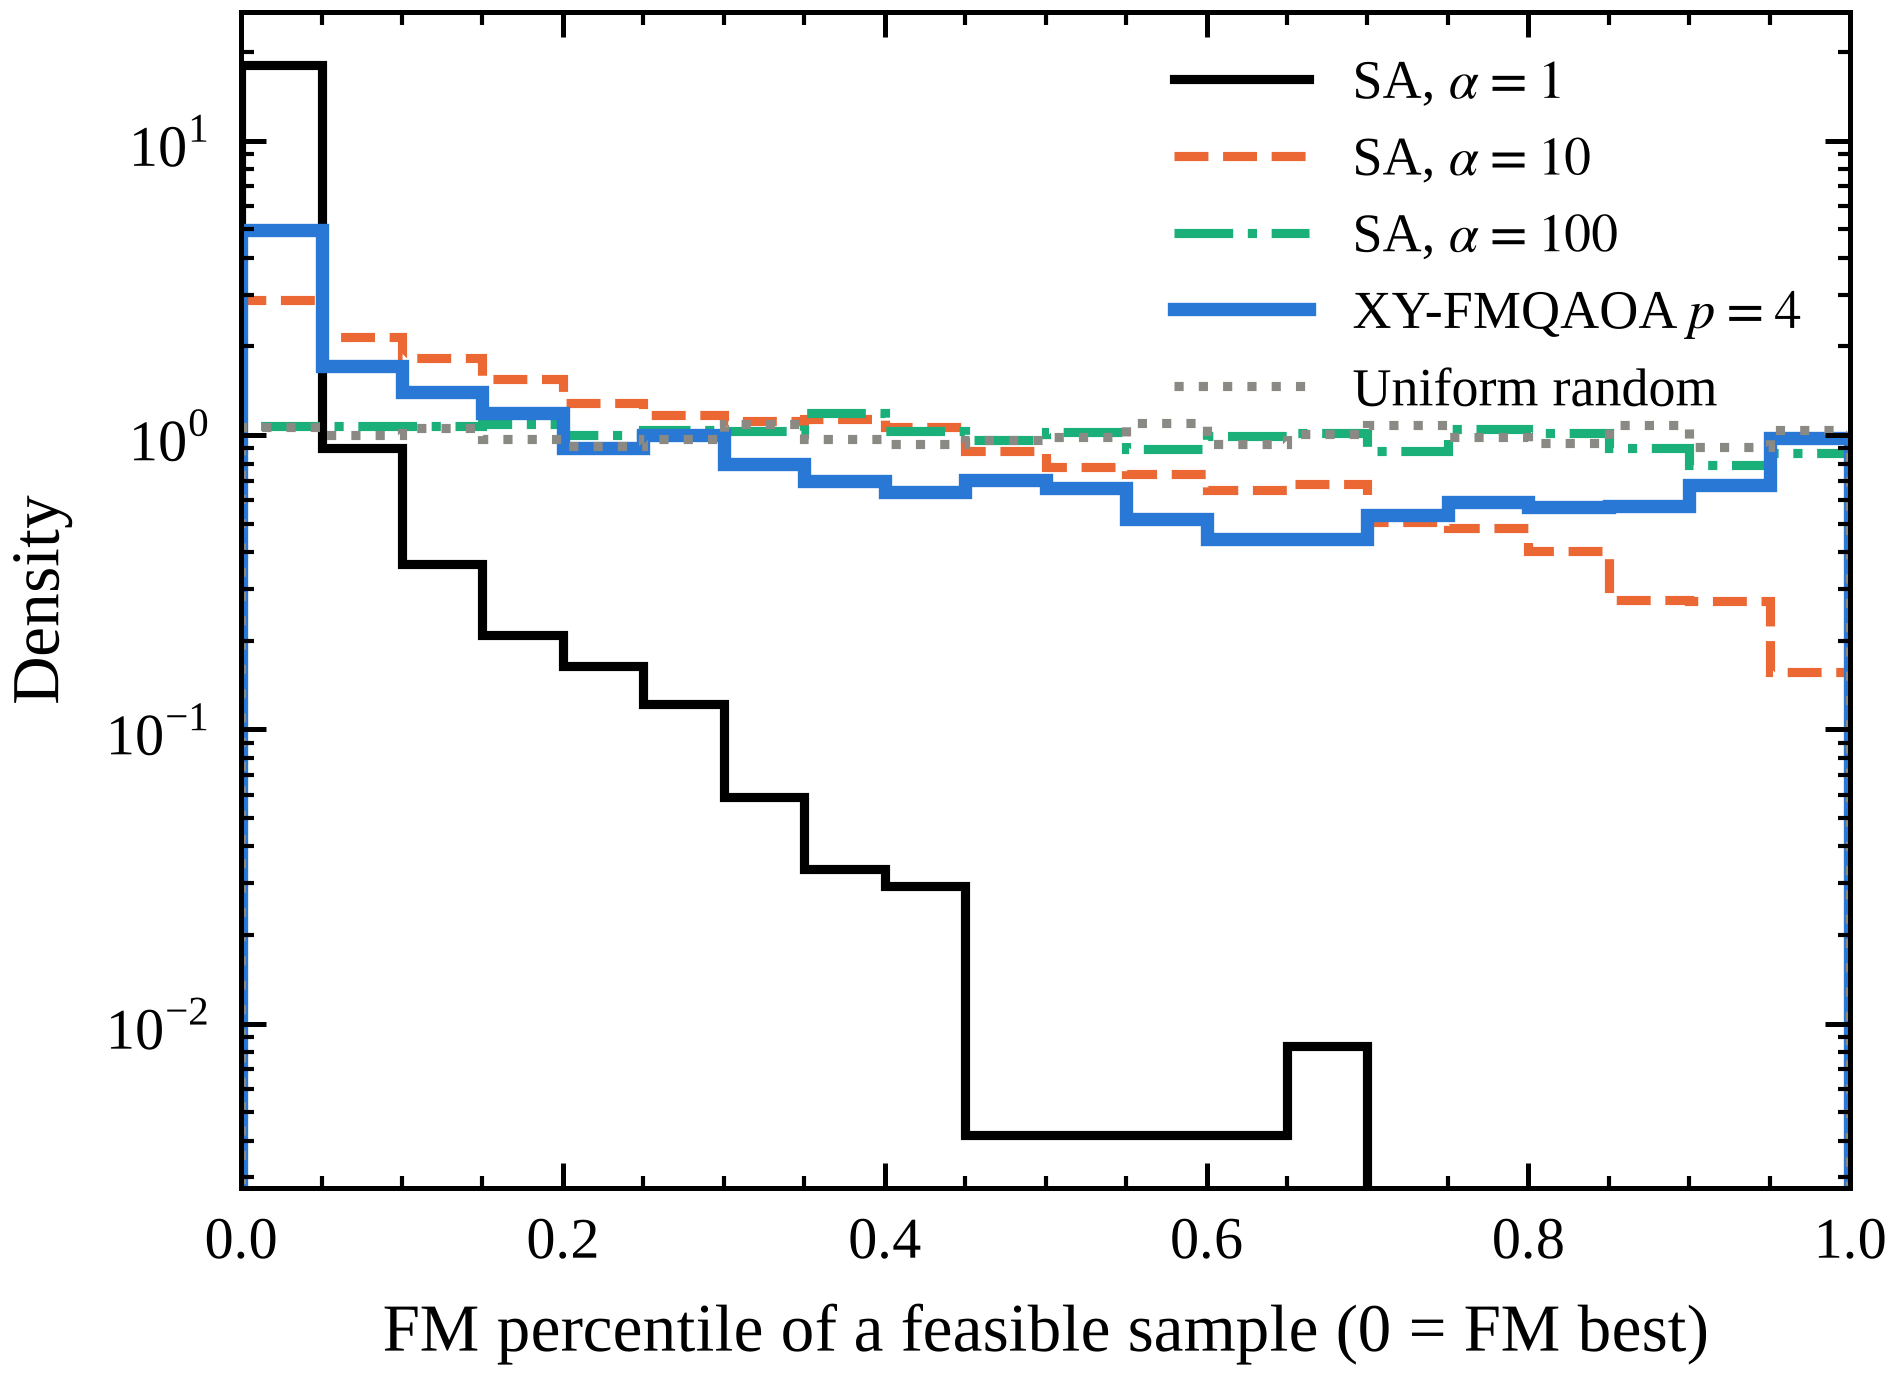

In [6]:
display(Image('png/energy_hist.png'))

## 図 6: 閉ループで XY が強い仕組み(`loop_mechanism`)
- 横軸: 提案サイクル。縦軸: (a) 選ばれた候補の真の順位(対数、15 Seed の中央値、5 サイクルの移動平均)、(b) 未評価の FM 最小を選んだ割合、(c) 1 サイクルで出た新しい実行可能候補の数
- 見るところ: α=1 の SA は FM 最小ばかり選び(b で 0.8〜0.95)、候補の種類が少ない(c で 20〜55)。XY は FM 最小を選ぶのは 1〜2 割だが、85〜98 種類の多様な候補を出し、選ぶ候補の真の順位は α=100・ランダム提案より良い
- 解釈(仮説): FM の予測が粗い問題では、FM の良い領域から多様に提案することが探索に有利

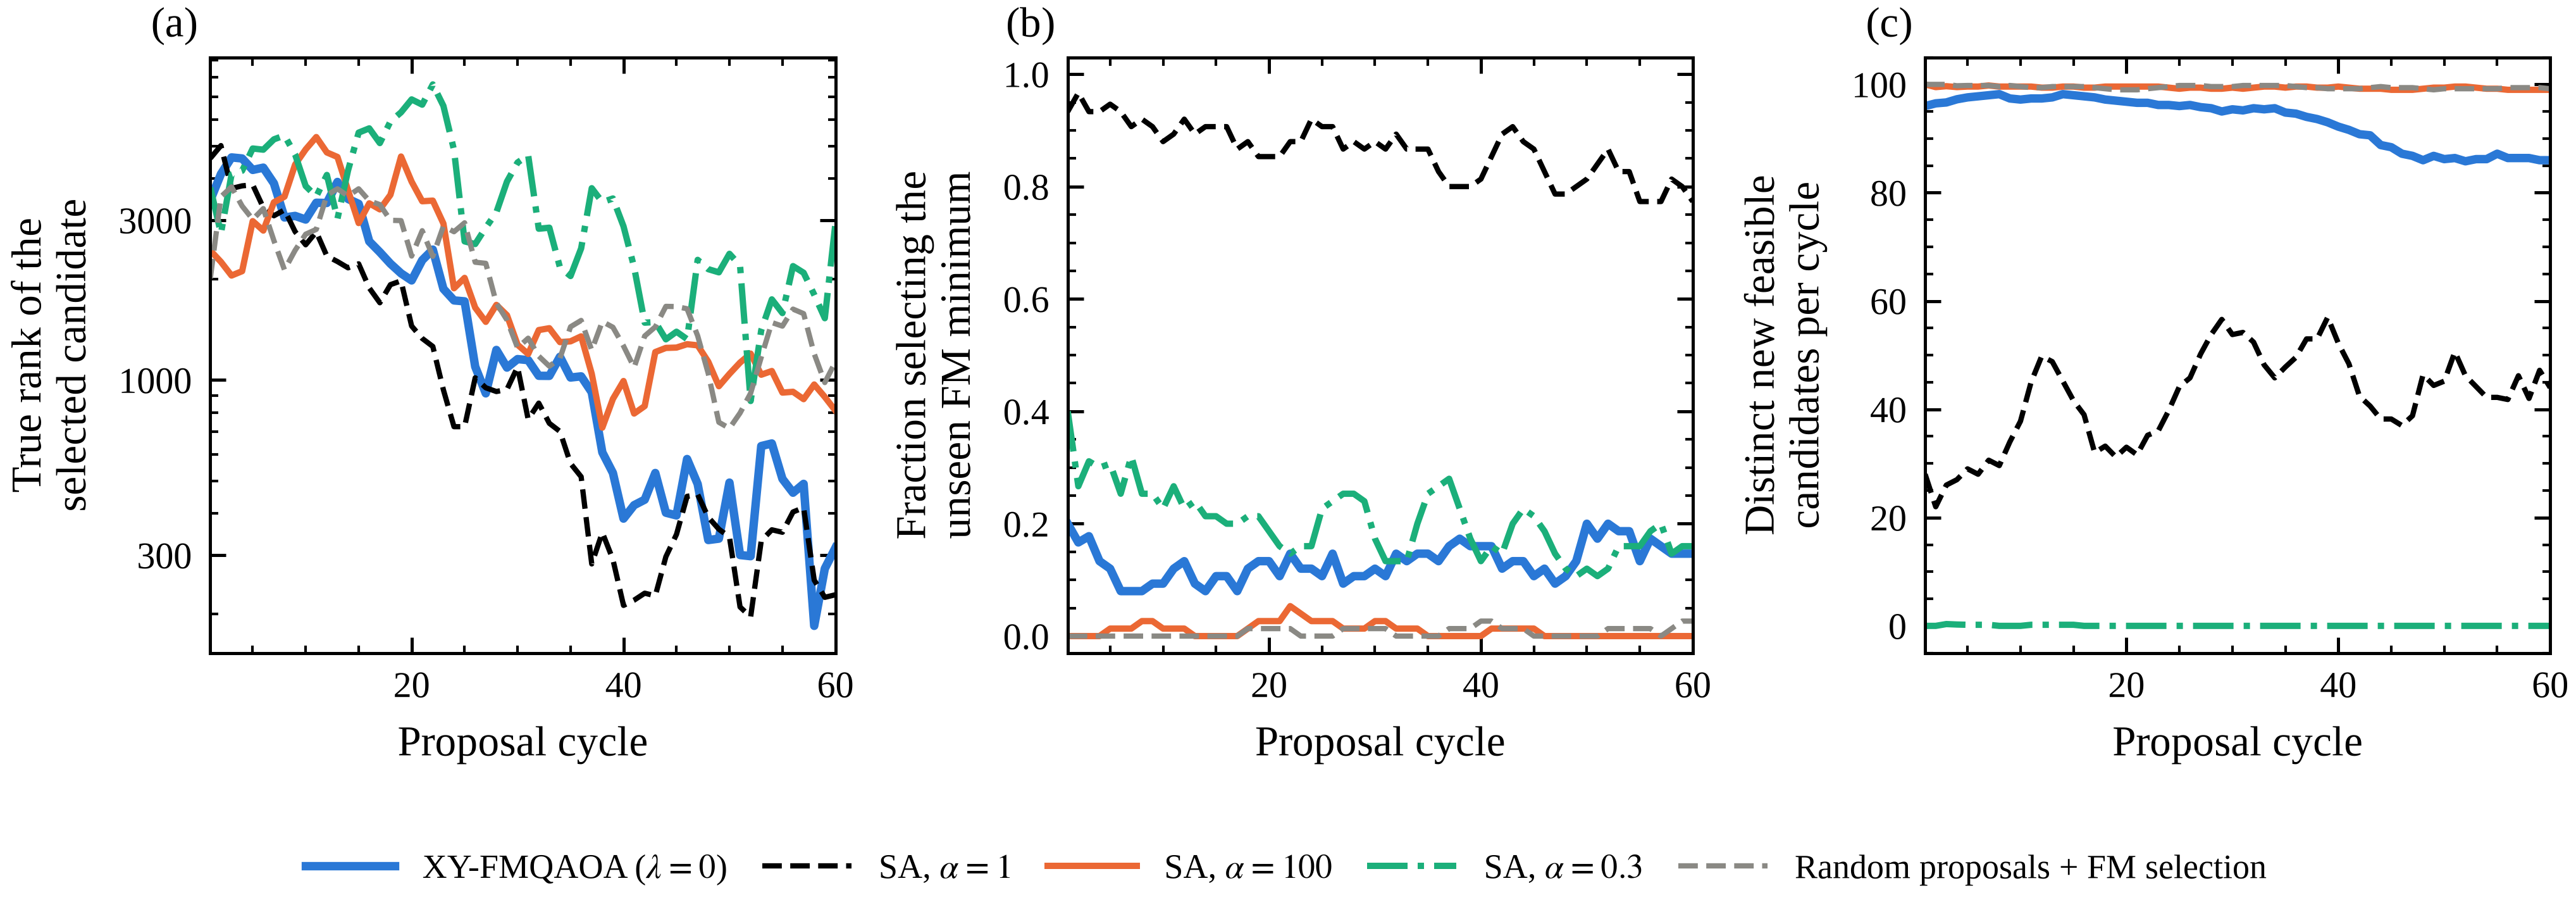

In [7]:
display(Image('png/loop_mechanism.png'))

## 図 7: 古典の提案器との比較: 正確さより分布の形(`shape_tau_sweep`)
- 横軸: 温度付き分布 p ∝ exp(−FM/T)、T = τ × std(FM) の温度 τ(対数、右ほど広い分布)。縦軸: 閉ループ(L=7、Seed 5001〜5015、評価 100 回)で最適解に到達した Seed の割合(大きいほど良い)
- 緑の点と線 = 温度付き分布。水平線: 青 = XY-FMQAOA、黒破線 = SA α=1(調整済みの罰則法)、橙破線 = カテゴリ型 SA(FM 最小解を正確に出す罰則なしの SA)
- 見るところ: 固定 FM で最も正確なカテゴリ型 SA が閉ループでは低く、τ=0.2 付近の広がりで最も良い
- 限界: 探索的な比較(15 Seed、検定は未補正)。τ=0.2 は同じ Seed での最良値なので楽観的。新しい 30 Seed での確認は図 8
- 入力: classical-baselines run(`csv/classical_loop.csv`)、XY・α は確認実験 run の再利用

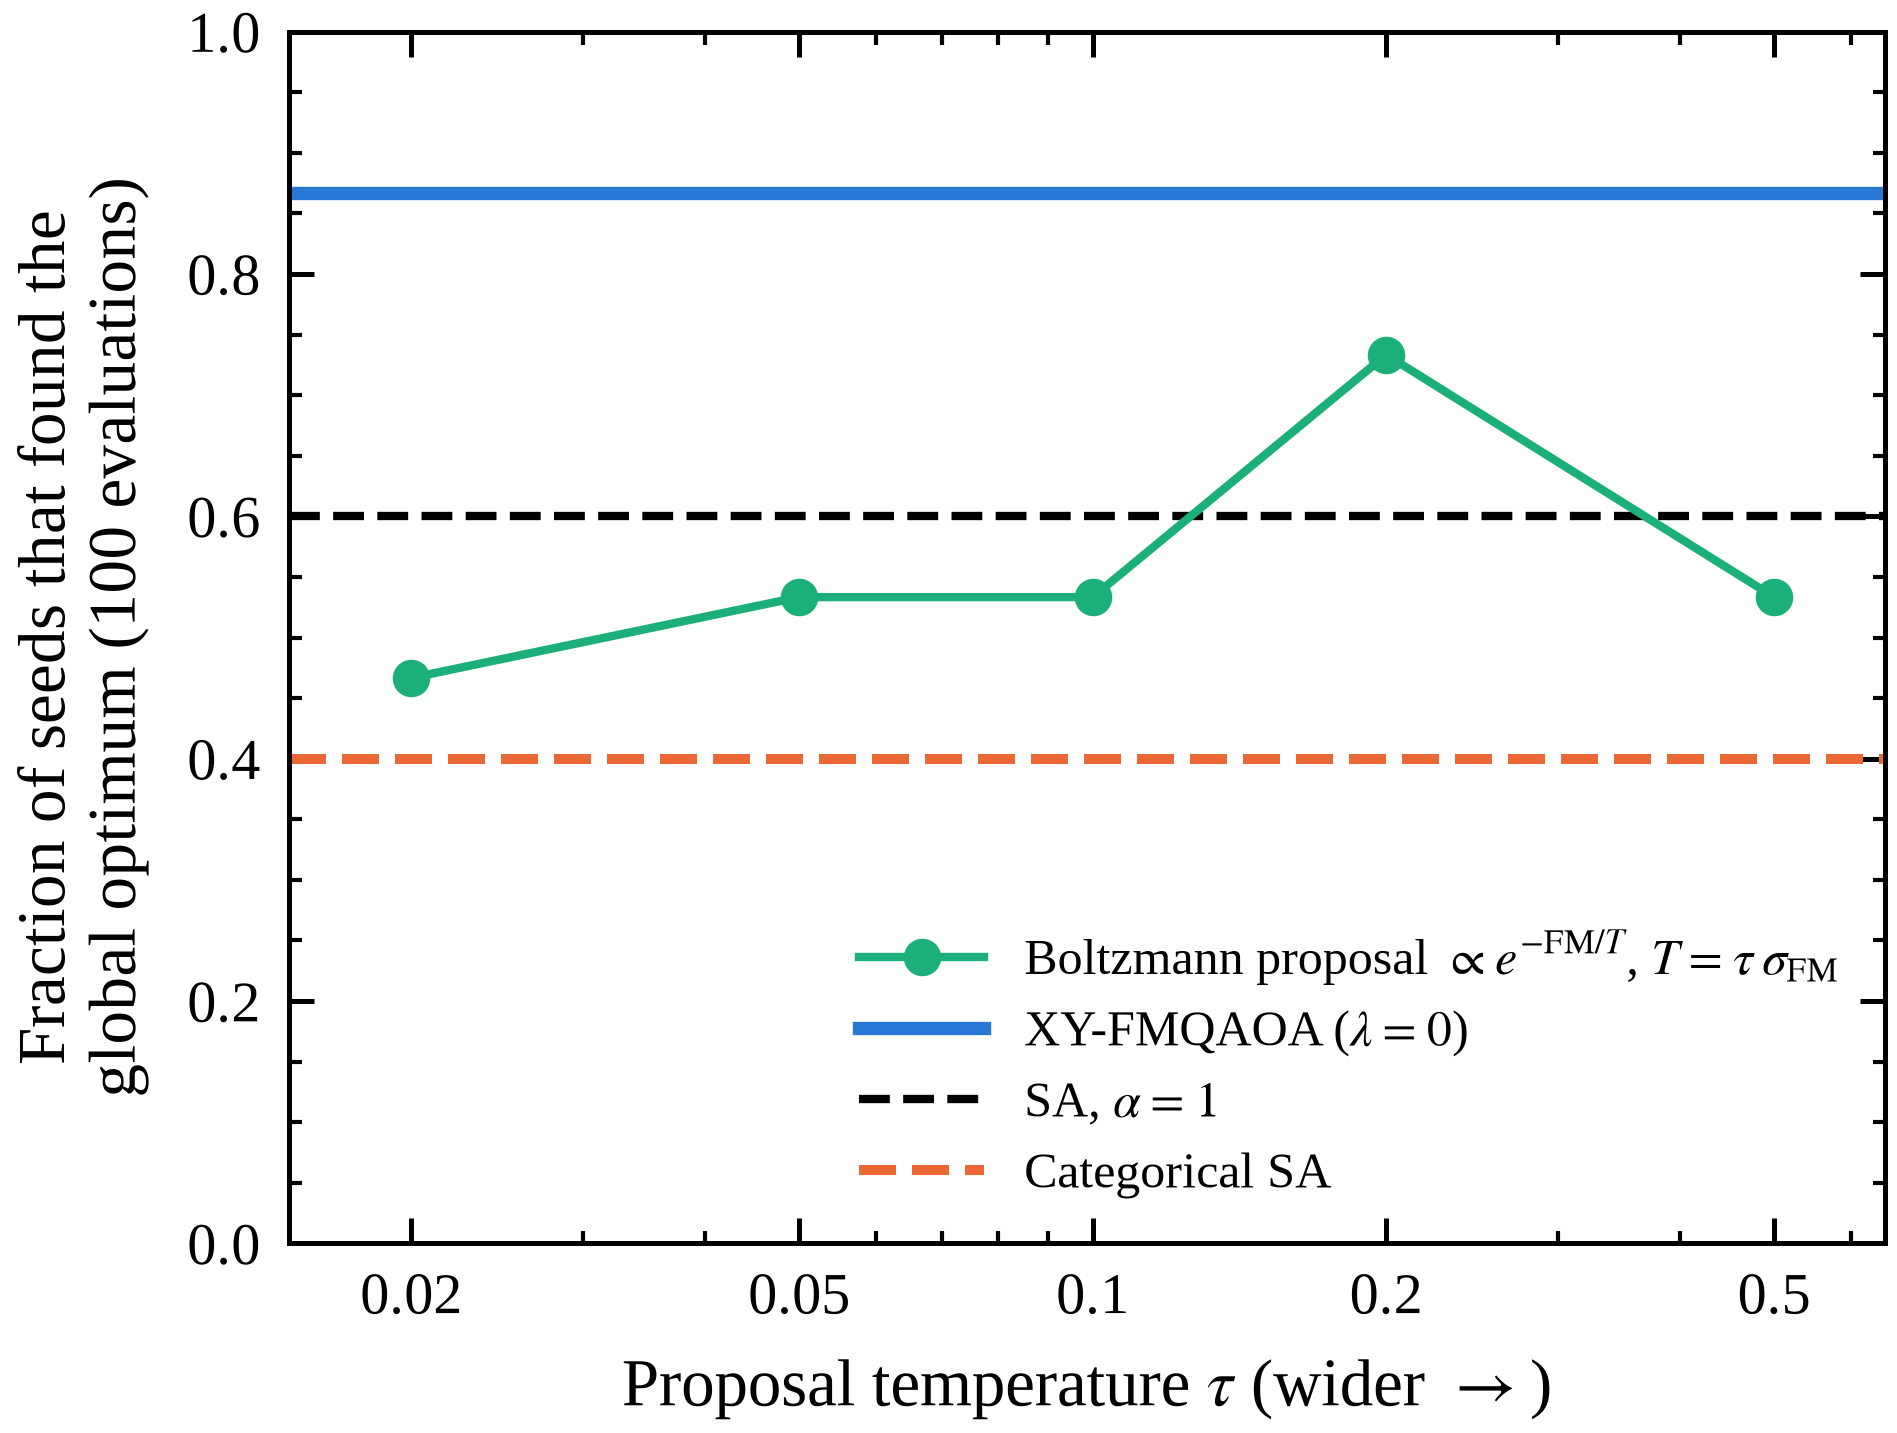

In [8]:
display(Image('png/shape_tau_sweep.png'))

## 図 8: 第 2 確認実験(`confirm2`)
- 横軸: 評価回数(初期 40 点を含む)。縦軸: (a) それまでの最良解の真の順位(対数、30 Seed の中央値、小さいほど良い)、(b) 最適解に到達した Seed の割合(大きいほど良い)
- 線: XY-FMQAOA、温度付き分布 τ=0.2、カテゴリ型 SA、SA α=1・100・0.3。α=0.3 は評価を使い切らずに終わるため最後の最良値を延長
- 比較: 実行前に固定した H1(XY < CatSA)、H2(Boltzmann τ=0.2 < CatSA)、H3(XY < α=100)。片側の対応のある Wilcoxon、Bonferroni ×3。下の表に検定結果
- 入力: bbo-confirm2 run(`csv/confirm2_final.csv`、`csv/confirm2_curves.csv`)。Seed 6001〜6030 は他のどの段階とも重ならない

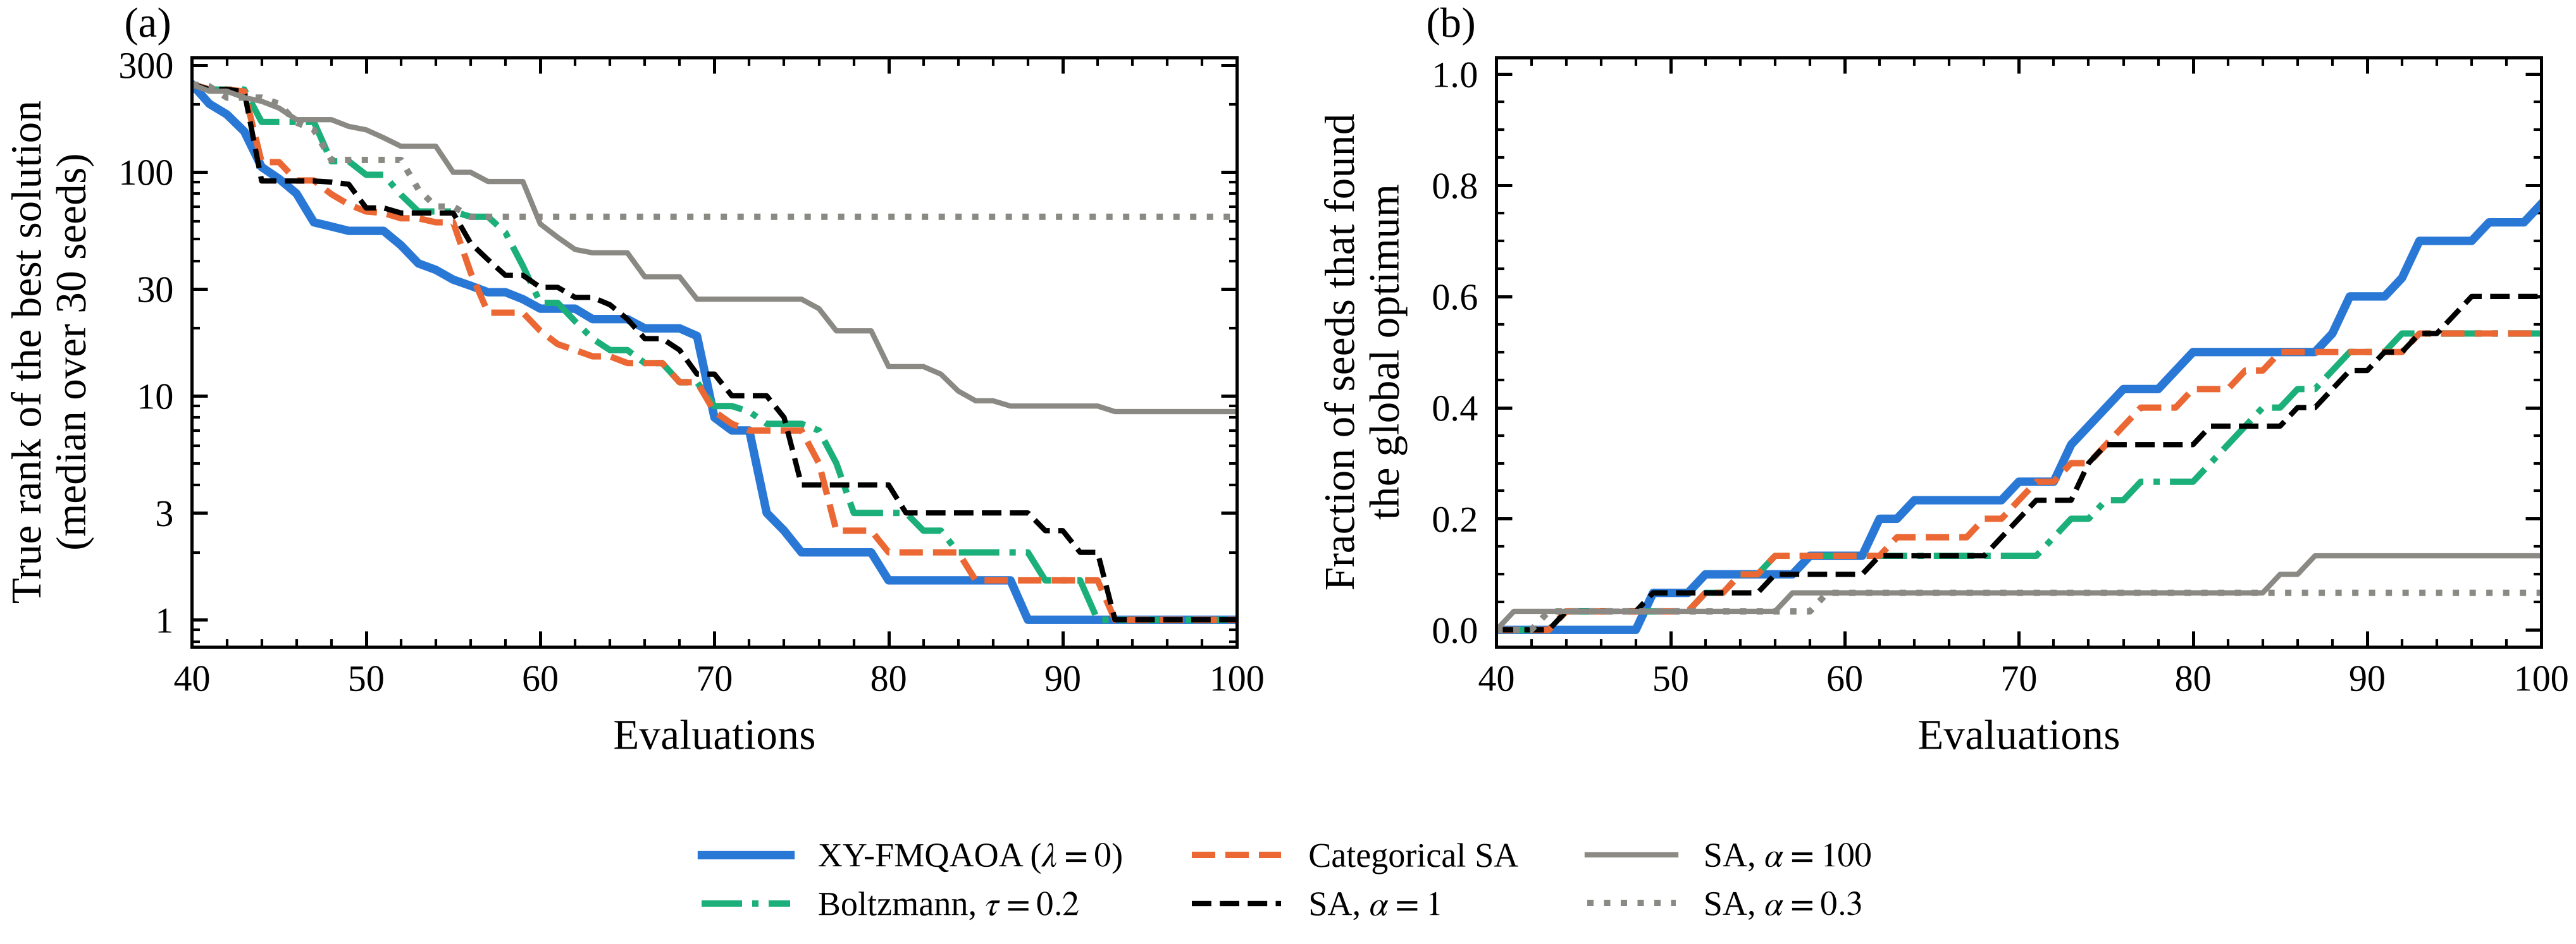

XY-FMQAOA {'n': 30, 'successes': 23, 'best_rank': [1.0, 1.0, 1.0], 'first_top10': [70.0, 49.75, 79.75]}
Boltzmann-t0.2 {'n': 30, 'successes': 16, 'best_rank': [1.0, 1.0, 6.0], 'first_top10': [69.0, 55.25, 79.75]}
CatSA {'n': 30, 'successes': 16, 'best_rank': [1.0, 1.0, 3.0], 'first_top10': [69.0, 54.5, 82.25]}
alpha1 {'n': 30, 'successes': 18, 'best_rank': [1.0, 1.0, 3.0], 'first_top10': [70.0, 57.0, 80.5]}
alpha100 {'n': 30, 'successes': 4, 'best_rank': [8.5, 2.25, 22.0], 'first_top10': [84.5, 62.25, 101.0]}
alpha0.3 {'n': 30, 'successes': 2, 'best_rank': [63.0, 14.0, 191.0], 'first_top10': [101.0, 101.0, 101.0]}
RandomFM {'n': 30, 'successes': 3, 'best_rank': [8.5, 3.0, 24.25], 'first_top10': [88.5, 70.75, 101.0]}
H1 {'first_better': 9, 'ties': 15, 'first_worse': 6, 'p_raw': 0.5, 'mcnemar_exact_p': 0.0654296875, 'pair': 'XY-FMQAOA vs CatSA', 'p_bonferroni': 1.0, 'supported': False}
H2 {'first_better': 8, 'ties': 13, 'first_worse': 9, 'p_raw': 0.6478626184526792, 'mcnemar_exact_p': 1.

In [9]:
import os
if os.path.exists('png/confirm2.png'): display(Image('png/confirm2.png'))
s = json.load(open(plot.RUNS/plot.CONFIG['runs']['confirm2']/'raw/summary.json')) if (plot.RUNS/plot.CONFIG['runs']['confirm2']/'raw/summary.json').exists() else None
if s:
    for k, v in s['summary'].items(): print(k, v)
    for k, v in s['tests'].items(): print(k, {q: v[q] for q in v if q in ('pair','first_better','ties','first_worse','p_raw','p_bonferroni','supported','mcnemar_exact_p')})

## 補足図: L=6・7・8 の閉ループ(探索、5 Seed)(`si_closed_loop_L678`)
- 縦軸: 最良解の真の順位(5 Seed の中央値)。L=6 は大きい α でも最適解に届き差が小さい。L=8 は Seed 間のばらつきが大きい

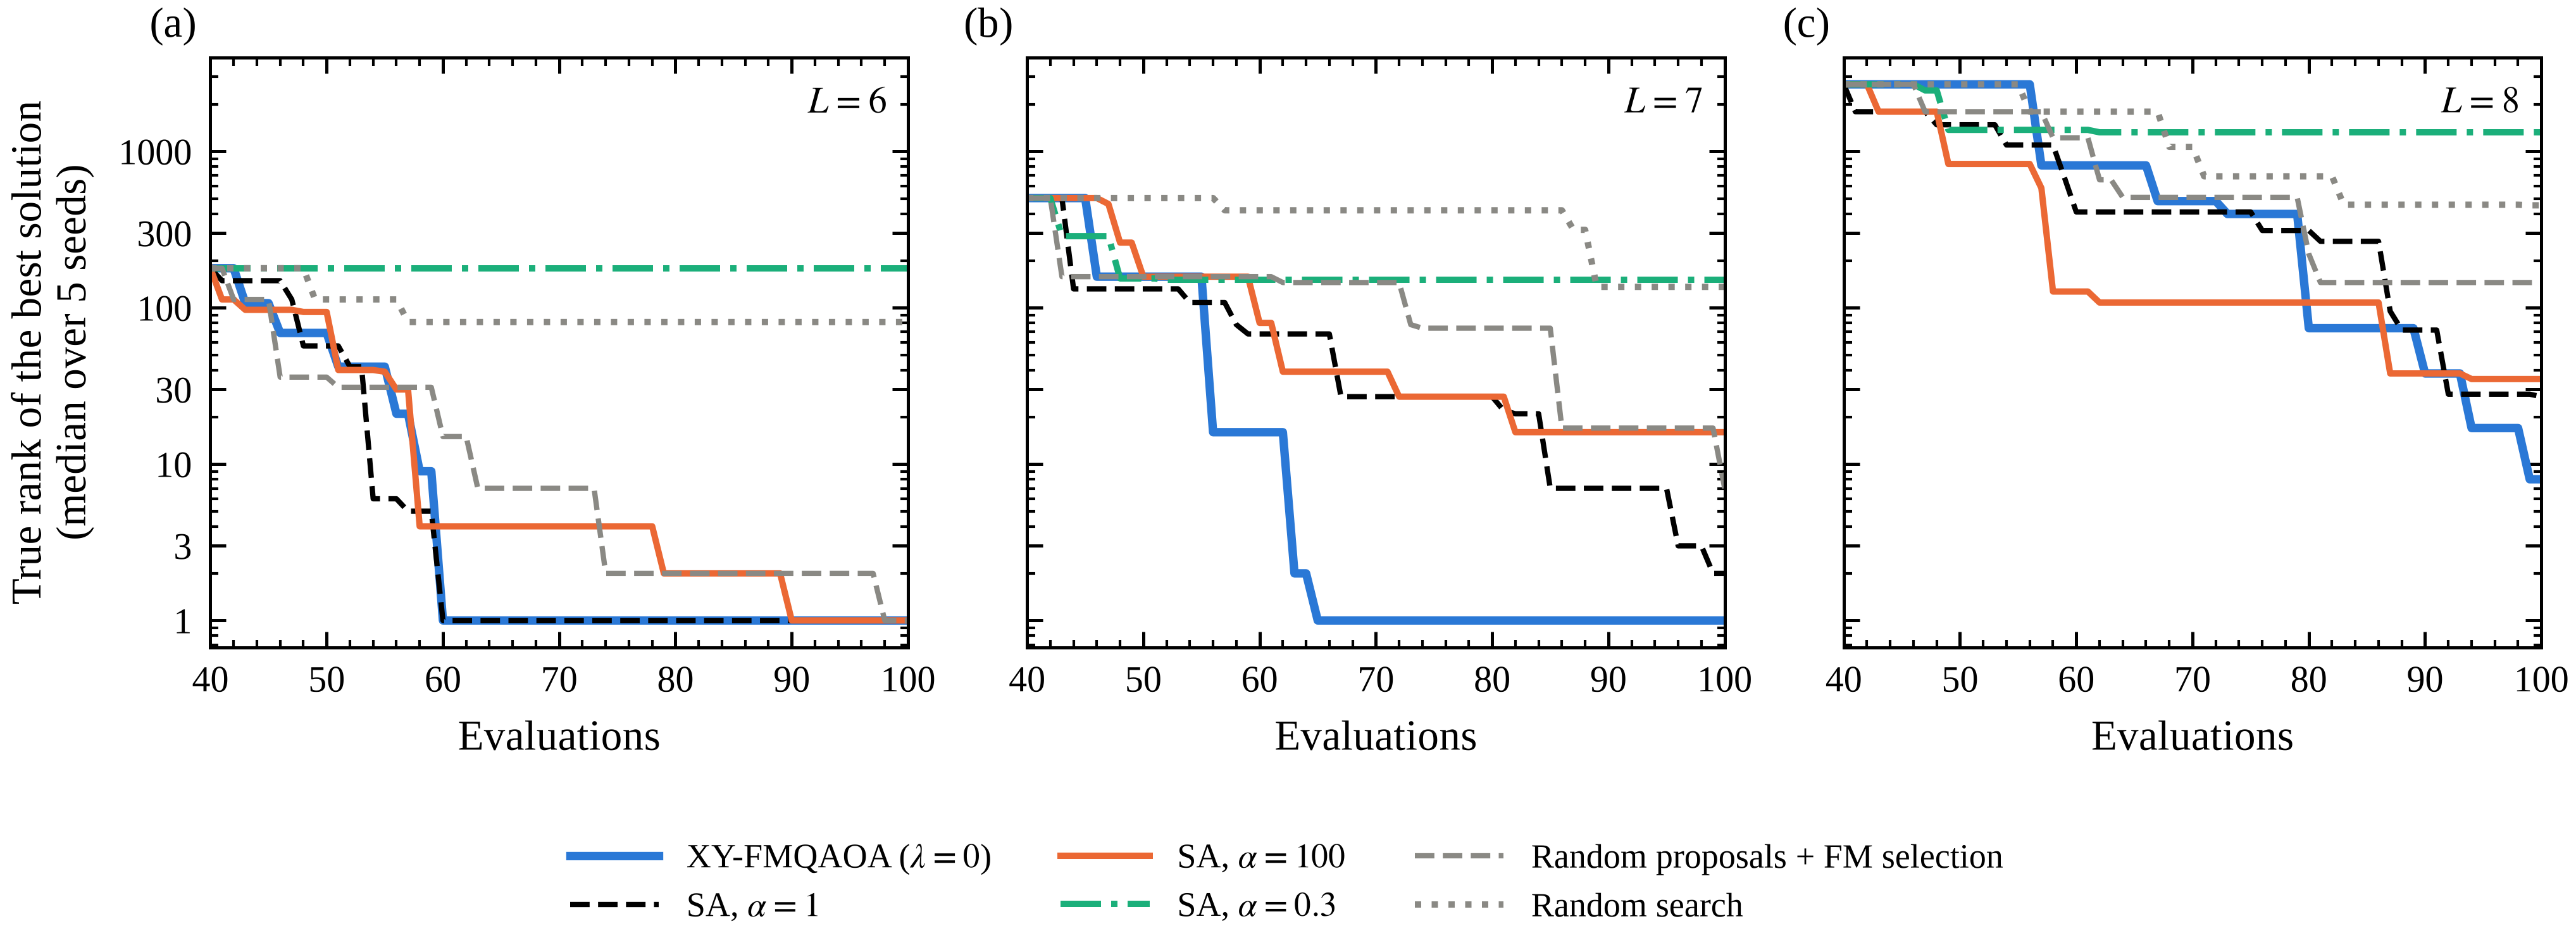

In [10]:
display(Image('png/si_closed_loop_L678.png'))

## 表: 計算コスト(確認実験、1 サイクルあたり)

In [11]:
for r in csv.DictReader(open('csv/compute_cost.csv')): print(r)

{'condition': 'XY-FMQAOA', 'cycles': '900', 'median_proposal_seconds': '24.296345641836524', 'first_cycle_proposal_seconds_median': '935.6103626051918', 'later_cycles_proposal_seconds_median': '24.285174215212464', 'median_training_seconds': '0.0753330229781568', 'median_angle_evaluations_per_cycle': '256.0'}
{'condition': 'alpha1', 'cycles': '900', 'median_proposal_seconds': '0.03965166350826621', 'first_cycle_proposal_seconds_median': '0.19244970474392176', 'later_cycles_proposal_seconds_median': '0.03959724213927984', 'median_training_seconds': '0.0726828989572823', 'median_angle_evaluations_per_cycle': ''}
{'condition': 'alpha100', 'cycles': '900', 'median_proposal_seconds': '0.025291291065514088', 'first_cycle_proposal_seconds_median': '0.25069720577448606', 'later_cycles_proposal_seconds_median': '0.025255031883716583', 'median_training_seconds': '0.07346297055482864', 'median_angle_evaluations_per_cycle': ''}
{'condition': 'alpha0.3', 'cycles': '900', 'median_proposal_seconds': 

## 全図の保存

In [12]:
plot.draw_all()

figures written to /home/jovyan/FMA/Fujitsu_OpenQarp/analysis/mlfilter-scale/paper
